In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("Sleep_health_and_lifestyle_dataset.csv")
df

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
...,...,...,...,...,...,...,...,...,...,...,...,...,...
369,370,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
370,371,Female,59,Nurse,8.0,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
371,372,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
372,373,Female,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea


In [3]:
df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [4]:
df.shape

(374, 13)

In [5]:
df.columns.tolist()

['Person ID',
 'Gender',
 'Age',
 'Occupation',
 'Sleep Duration',
 'Quality of Sleep',
 'Physical Activity Level',
 'Stress Level',
 'BMI Category',
 'Blood Pressure',
 'Heart Rate',
 'Daily Steps',
 'Sleep Disorder']

In [6]:
df.isnull().sum()

Person ID                    0
Gender                       0
Age                          0
Occupation                   0
Sleep Duration               0
Quality of Sleep             0
Physical Activity Level      0
Stress Level                 0
BMI Category                 0
Blood Pressure               0
Heart Rate                   0
Daily Steps                  0
Sleep Disorder             219
dtype: int64

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    str    
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    str    
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    str    
 9   Blood Pressure           374 non-null    str    
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    str    
dtypes: float64(1), int64(7), str(5)
memory usage: 38.1 KB


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df["Sleep Disorder"].value_counts(dropna=False)

Sleep Disorder
NaN            219
Sleep Apnea     78
Insomnia        77
Name: count, dtype: int64

In [10]:
len(df)

374

In [11]:
df.loc[
    df["Sleep Disorder"].isnull(),
    ["Age","Sleep Duration","Quality of Sleep","Stress Level","BMI Category"]].head(10)

,Age,Sleep Duration,Quality of Sleep,Stress Level,BMI Category
0,27,6.1,6,6,Overweight
1,28,6.2,6,8,Normal
2,28,6.2,6,8,Normal
7,29,7.8,7,6,Normal
8,29,7.8,7,6,Normal
9,29,7.8,7,6,Normal
10,29,6.1,6,8,Normal
11,29,7.8,7,6,Normal
12,29,6.1,6,8,Normal
13,29,6.0,6,8,Normal


In [12]:
df.describe()

,Person ID,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps
count,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000
mean,187.500000,42.184492,7.132086,7.312834,59.171123,5.385027,70.165775,6816.844920
std,108.108742,8.673133,0.795657,1.196956,20.830804,1.774526,4.135676,1617.915679
min,1.000000,27.000000,5.800000,4.000000,30.000000,3.000000,65.000000,3000.000000
25%,94.250000,35.250000,6.400000,6.000000,45.000000,4.000000,68.000000,5600.000000
50%,187.500000,43.000000,7.200000,7.000000,60.000000,5.000000,70.000000,7000.000000
75%,280.750000,50.000000,7.800000,8.000000,75.000000,7.000000,72.000000,8000.000000
max,374.000000,59.000000,8.500000,9.000000,90.000000,8.000000,86.000000,10000.000000


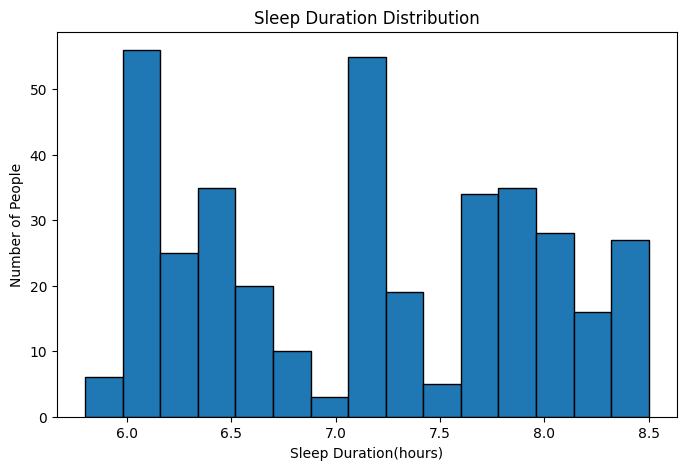

In [13]:
plt.figure(figsize=(8,5))
plt.hist(df["Sleep Duration"],bins=15,edgecolor="black")
plt.xlabel("Sleep Duration(hours)")
plt.ylabel("Number of People")
plt.title("Sleep Duration Distribution")
plt.show()

In [14]:
missing_count=df["Sleep Disorder"].isnull().sum()
total_rows=len(df)
print("Missing values :",missing_count)
print("total_rows value :",total_rows)

Missing values : 219
total_rows value : 374


In [15]:
print("missing percentage :",round(missing_count/total_rows *100,2),"%")

missing percentage : 58.56 %


In [16]:
df["Gender"].value_counts()

Gender
Male      189
Female    185
Name: count, dtype: int64

In [17]:
df["Gender"]=df["Gender"].map({"Male":0,"Female":1})

In [18]:
df

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,0,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,0,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,0,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,0,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,0,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
...,...,...,...,...,...,...,...,...,...,...,...,...,...
369,370,1,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
370,371,1,59,Nurse,8.0,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
371,372,1,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
372,373,1,59,Nurse,8.1,9,75,3,Overweight,140/95,68,7000,Sleep Apnea


In [19]:
df["Occupation"].value_counts()

Occupation
Nurse                   73
Doctor                  71
Engineer                63
Lawyer                  47
Teacher                 40
Accountant              37
Salesperson             32
Software Engineer        4
Scientist                4
Sales Representative     2
Manager                  1
Name: count, dtype: int64

In [20]:
df=pd.get_dummies(df,columns=["Occupation"],drop_first=True,dtype=int)

In [21]:
df

,Person ID,Gender,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,...,Occupation_Doctor,Occupation_Engineer,Occupation_Lawyer,Occupation_Manager,Occupation_Nurse,Occupation_Sales Representative,Occupation_Salesperson,Occupation_Scientist,Occupation_Software Engineer,Occupation_Teacher
0,1,0,27,6.1,6,42,6,Overweight,126/83,77,...,0,0,0,0,0,0,0,0,1,0
1,2,0,28,6.2,6,60,8,Normal,125/80,75,...,1,0,0,0,0,0,0,0,0,0
2,3,0,28,6.2,6,60,8,Normal,125/80,75,...,1,0,0,0,0,0,0,0,0,0
3,4,0,28,5.9,4,30,8,Obese,140/90,85,...,0,0,0,0,0,1,0,0,0,0
4,5,0,28,5.9,4,30,8,Obese,140/90,85,...,0,0,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
369,370,1,59,8.1,9,75,3,Overweight,140/95,68,...,0,0,0,0,1,0,0,0,0,0
370,371,1,59,8.0,9,75,3,Overweight,140/95,68,...,0,0,0,0,1,0,0,0,0,0
371,372,1,59,8.1,9,75,3,Overweight,140/95,68,...,0,0,0,0,1,0,0,0,0,0
372,373,1,59,8.1,9,75,3,Overweight,140/95,68,...,0,0,0,0,1,0,0,0,0,0


In [22]:
df=pd.get_dummies(df,columns=["BMI Category"],drop_first=True,dtype=int)

In [23]:
df.head(20)

,Person ID,Gender,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Blood Pressure,Heart Rate,Daily Steps,...,Occupation_Manager,Occupation_Nurse,Occupation_Sales Representative,Occupation_Salesperson,Occupation_Scientist,Occupation_Software Engineer,Occupation_Teacher,BMI Category_Normal Weight,BMI Category_Obese,BMI Category_Overweight
0,1,0,27,6.1,6,42,6,126/83,77,4200,...,0,0,0,0,0,1,0,0,0,1
1,2,0,28,6.2,6,60,8,125/80,75,10000,...,0,0,0,0,0,0,0,0,0,0
2,3,0,28,6.2,6,60,8,125/80,75,10000,...,0,0,0,0,0,0,0,0,0,0
3,4,0,28,5.9,4,30,8,140/90,85,3000,...,0,0,1,0,0,0,0,0,1,0
4,5,0,28,5.9,4,30,8,140/90,85,3000,...,0,0,1,0,0,0,0,0,1,0
5,6,0,28,5.9,4,30,8,140/90,85,3000,...,0,0,0,0,0,1,0,0,1,0
6,7,0,29,6.3,6,40,7,140/90,82,3500,...,0,0,0,0,0,0,1,0,1,0
7,8,0,29,7.8,7,75,6,120/80,70,8000,...,0,0,0,0,0,0,0,0,0,0
8,9,0,29,7.8,7,75,6,120/80,70,8000,...,0,0,0,0,0,0,0,0,0,0
9,10,0,29,7.8,7,75,6,120/80,70,8000,...,0,0,0,0,0,0,0,0,0,0


In [24]:
df[["Systolic BP", "Diastolic BP"]] = (
    df["Blood Pressure"]
    .str.split("/", expand=True)
    .astype(int)
)

In [25]:
df.head()

,Person ID,Gender,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Blood Pressure,Heart Rate,Daily Steps,...,Occupation_Sales Representative,Occupation_Salesperson,Occupation_Scientist,Occupation_Software Engineer,Occupation_Teacher,BMI Category_Normal Weight,BMI Category_Obese,BMI Category_Overweight,Systolic BP,Diastolic BP
0,1,0,27,6.1,6,42,6,126/83,77,4200,...,0,0,0,1,0,0,0,1,126,83
1,2,0,28,6.2,6,60,8,125/80,75,10000,...,0,0,0,0,0,0,0,0,125,80
2,3,0,28,6.2,6,60,8,125/80,75,10000,...,0,0,0,0,0,0,0,0,125,80
3,4,0,28,5.9,4,30,8,140/90,85,3000,...,1,0,0,0,0,0,1,0,140,90
4,5,0,28,5.9,4,30,8,140/90,85,3000,...,1,0,0,0,0,0,1,0,140,90


In [26]:
df.drop("Blood Pressure", axis=1, inplace=True)

In [27]:
df.head()

,Person ID,Gender,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps,Sleep Disorder,...,Occupation_Sales Representative,Occupation_Salesperson,Occupation_Scientist,Occupation_Software Engineer,Occupation_Teacher,BMI Category_Normal Weight,BMI Category_Obese,BMI Category_Overweight,Systolic BP,Diastolic BP
0,1,0,27,6.1,6,42,6,77,4200,NaN,...,0,0,0,1,0,0,0,1,126,83
1,2,0,28,6.2,6,60,8,75,10000,NaN,...,0,0,0,0,0,0,0,0,125,80
2,3,0,28,6.2,6,60,8,75,10000,NaN,...,0,0,0,0,0,0,0,0,125,80
3,4,0,28,5.9,4,30,8,85,3000,Sleep Apnea,...,1,0,0,0,0,0,1,0,140,90
4,5,0,28,5.9,4,30,8,85,3000,Sleep Apnea,...,1,0,0,0,0,0,1,0,140,90


In [28]:
df.isnull().sum()

Person ID                            0
Gender                               0
Age                                  0
Sleep Duration                       0
Quality of Sleep                     0
Physical Activity Level              0
Stress Level                         0
Heart Rate                           0
Daily Steps                          0
Sleep Disorder                     219
Occupation_Doctor                    0
Occupation_Engineer                  0
Occupation_Lawyer                    0
Occupation_Manager                   0
Occupation_Nurse                     0
Occupation_Sales Representative      0
Occupation_Salesperson               0
Occupation_Scientist                 0
Occupation_Software Engineer         0
Occupation_Teacher                   0
BMI Category_Normal Weight           0
BMI Category_Obese                   0
BMI Category_Overweight              0
Systolic BP                          0
Diastolic BP                         0
dtype: int64

In [29]:
df_clean=df.dropna(subset=["Sleep Disorder"]).copy()

In [30]:
df_clean.drop("Person ID",axis=1,inplace=True)

In [31]:
df_clean.shape

(155, 24)

In [32]:
X=df_clean.drop("Sleep Disorder",axis=1)
y=df_clean["Sleep Disorder"]

In [33]:
print("X shape:",X.shape)
print("y shape:",y.shape)

X shape: (155, 23)
y shape: (155,)


In [34]:
from sklearn.model_selection import train_test_split

In [35]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [36]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(124, 23)
(31, 23)
(124,)
(31,)


In [37]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()

In [38]:
X_trained=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [39]:
print(X_trained.shape)
print(X_test_scaled.shape)

(124, 23)
(31, 23)


In [40]:
print(y_train.value_counts())
print(y_test.value_counts())

Sleep Disorder
Insomnia       62
Sleep Apnea    62
Name: count, dtype: int64
Sleep Disorder
Sleep Apnea    16
Insomnia       15
Name: count, dtype: int64


In [41]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()

In [42]:
model.fit(X_trained,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [43]:
y_pred=model.predict(X_test_scaled)

In [44]:
y_pred

array(['Sleep Apnea', 'Insomnia', 'Sleep Apnea', 'Insomnia',
       'Sleep Apnea', 'Insomnia', 'Sleep Apnea', 'Insomnia', 'Insomnia',
       'Sleep Apnea', 'Sleep Apnea', 'Insomnia', 'Insomnia',
       'Sleep Apnea', 'Insomnia', 'Sleep Apnea', 'Sleep Apnea',
       'Sleep Apnea', 'Sleep Apnea', 'Insomnia', 'Sleep Apnea',
       'Insomnia', 'Insomnia', 'Sleep Apnea', 'Insomnia', 'Insomnia',
       'Sleep Apnea', 'Sleep Apnea', 'Insomnia', 'Insomnia', 'Insomnia'],
      dtype=object)

In [45]:
print(pd.DataFrame(y_pred))

              0
0   Sleep Apnea
1      Insomnia
2   Sleep Apnea
3      Insomnia
4   Sleep Apnea
5      Insomnia
6   Sleep Apnea
7      Insomnia
8      Insomnia
9   Sleep Apnea
10  Sleep Apnea
11     Insomnia
12     Insomnia
13  Sleep Apnea
14     Insomnia
15  Sleep Apnea
16  Sleep Apnea
17  Sleep Apnea
18  Sleep Apnea
19     Insomnia
20  Sleep Apnea
21     Insomnia
22     Insomnia
23  Sleep Apnea
24     Insomnia
25     Insomnia
26  Sleep Apnea
27  Sleep Apnea
28     Insomnia
29     Insomnia
30     Insomnia


In [46]:
comparison=pd.DataFrame({"Actual":y_test.values,
                         "predicted":y_pred})

In [47]:
comparison

,Actual,predicted
0,Sleep Apnea,Sleep Apnea
1,Insomnia,Insomnia
2,Sleep Apnea,Sleep Apnea
3,Insomnia,Insomnia
4,Sleep Apnea,Sleep Apnea
5,Insomnia,Insomnia
6,Sleep Apnea,Sleep Apnea
7,Insomnia,Insomnia
8,Insomnia,Insomnia
9,Sleep Apnea,Sleep Apnea


In [48]:
from sklearn.metrics import accuracy_score
accuracy=accuracy_score(y_test,y_pred)

In [49]:
accuracy

0.8387096774193549

In [50]:
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred)

In [51]:
cm

array([[13,  2],
       [ 3, 13]])

In [52]:
from sklearn.metrics import precision_score, recall_score, f1_score

print("Precision:", precision_score(y_test, y_pred, pos_label="Sleep Apnea"))
print("Recall:", recall_score(y_test, y_pred, pos_label="Sleep Apnea"))
print("F1 Score:", f1_score(y_test, y_pred, pos_label="Sleep Apnea"))

Precision: 0.8666666666666667
Recall: 0.8125
F1 Score: 0.8387096774193549


In [53]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    Insomnia       0.81      0.87      0.84        15
 Sleep Apnea       0.87      0.81      0.84        16

    accuracy                           0.84        31
   macro avg       0.84      0.84      0.84        31
weighted avg       0.84      0.84      0.84        31



In [54]:
from sklearn.model_selection import cross_val_score,StratifiedKFold

In [55]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

In [56]:
scores=cross_val_score(model,X_trained,y_train,cv=cv,scoring="accuracy")

In [57]:
print("scores :",scores)
print("scores_average:",scores.mean())
print("standard Deviation :", scores.std())

scores : [0.96       0.84       0.92       0.92       0.79166667]
scores_average: 0.8863333333333333
standard Deviation : 0.06132246280478669


In [58]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [59]:
pipeline=Pipeline([
    ("pipeline",StandardScaler()),
    ("model",LogisticRegression(max_iter=2000))
])

In [60]:
from sklearn.model_selection import cross_val_score,StratifiedKFold


In [61]:
cv=StratifiedKFold(n_splits=5,
                   shuffle=True,
                   random_state=42)

In [62]:
scores=cross_val_score(
    pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy")

In [63]:
print("fold score",scores)
print("mean accuracy",scores.mean())
print("Std",scores.std())

fold score [0.96       0.84       0.92       0.92       0.79166667]
mean accuracy 0.8863333333333333
Std 0.06132246280478669


In [64]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

models={"Logistic regression":LogisticRegression(max_iter=2000),
        "Decision Tree":DecisionTreeClassifier(random_state=42),
        "Random forest":RandomForestClassifier(random_state=42),
        "knn":KNeighborsClassifier()}

In [65]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", model)
    ])

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    results.append({
        "Model": name,
        "Mean Accuracy": scores.mean(),
        "Std": scores.std()
    })

    print(f"{name}: {scores}")

Logistic regression: [0.96       0.84       0.92       0.92       0.79166667]
Decision Tree: [0.88       0.76       0.92       0.92       0.79166667]
Random forest: [0.88 0.8  0.92 0.88 0.75]
knn: [0.92       0.84       0.92       0.92       0.79166667]


In [66]:
results_df=pd.DataFrame(results)
results_df=results_df.sort_values(by="Mean Accuracy",ascending=False).reset_index(drop=True)

In [67]:
results_df

,Model,Mean Accuracy,Std
0,Logistic regression,0.886333,0.061322
1,knn,0.878333,0.053271
2,Decision Tree,0.854333,0.066496
3,Random forest,0.846000,0.061838


In [68]:
from sklearn.metrics import accuracy_score,classification_report
test_results=[]
for name,model in models.items():
    pipeline=Pipeline([
        ("scaler",StandardScaler()),
        ("model",model)
    ])
    pipeline.fit(X_train,y_train)
    y_pred=pipeline.predict(X_test)

    test_results.append({
        "Model":name,
        "Test Accuracy":accuracy_score(y_test,y_pred)
    })
    test_results_df=pd.DataFrame(test_results)

    test_results_df.sort_values(by="Test Accuracy",ascending=False).reset_index(drop=True)


In [69]:
test_results_df

,Model,Test Accuracy
0,Logistic regression,0.838710
1,Decision Tree,0.870968
2,Random forest,0.903226
3,knn,0.774194


In [70]:
from sklearn.metrics import classification_report,confusion_matrix


In [71]:
for name,model in models.items():
    pipeline=Pipeline([
        ("scaler",StandardScaler()),
        ("model",model)
    ])

    pipeline.fit(X_train,y_train)
    y_pred=pipeline.predict(X_test)

    print("="*50)
    print(name)
    print("="*50)
    print("Confusion Matrix:")
    print(confusion_matrix(y_test,y_pred))

    print("\nClassification Report:")
    print(classification_report(y_test,y_pred))

Logistic regression
Confusion Matrix:
[[13  2]
 [ 3 13]]

Classification Report:
              precision    recall  f1-score   support

    Insomnia       0.81      0.87      0.84        15
 Sleep Apnea       0.87      0.81      0.84        16

    accuracy                           0.84        31
   macro avg       0.84      0.84      0.84        31
weighted avg       0.84      0.84      0.84        31

Decision Tree
Confusion Matrix:
[[13  2]
 [ 2 14]]

Classification Report:
              precision    recall  f1-score   support

    Insomnia       0.87      0.87      0.87        15
 Sleep Apnea       0.88      0.88      0.88        16

    accuracy                           0.87        31
   macro avg       0.87      0.87      0.87        31
weighted avg       0.87      0.87      0.87        31

Random forest
Confusion Matrix:
[[14  1]
 [ 2 14]]

Classification Report:
              precision    recall  f1-score   support

    Insomnia       0.88      0.93      0.90        15
 Sleep

In [72]:
final_comparison=results_df.merge(
    test_results_df,
    on="Model"
)
final_comparison=final_comparison.sort_values(
    by="Mean Accuracy",
    ascending=False).reset_index(drop=True)

In [73]:
final_comparison

,Model,Mean Accuracy,Std,Test Accuracy
0,Logistic regression,0.886333,0.061322,0.838710
1,knn,0.878333,0.053271,0.774194
2,Decision Tree,0.854333,0.066496,0.870968
3,Random forest,0.846000,0.061838,0.903226


In [74]:
y_pred=pipeline.predict(X_test)
y_proba=pipeline.predict_proba(X_test)
print("Predictions:")
print(y_pred[:10])
print("\nPrediction Probabilities")
print(y_proba[:10])

Predictions:
['Sleep Apnea' 'Insomnia' 'Sleep Apnea' 'Insomnia' 'Sleep Apnea'
 'Insomnia' 'Sleep Apnea' 'Insomnia' 'Insomnia' 'Sleep Apnea']

Prediction Probabilities
[[0. 1.]
 [1. 0.]
 [0. 1.]
 [1. 0.]
 [0. 1.]
 [1. 0.]
 [0. 1.]
 [1. 0.]
 [1. 0.]
 [0. 1.]]


In [75]:
import numpy as np

np.set_printoptions(precision=10, suppress=False)

print("Classes:", pipeline.classes_)

print("\nExact probabilities:")
print(y_proba[:10])

Classes: ['Insomnia' 'Sleep Apnea']

Exact probabilities:
[[0. 1.]
 [1. 0.]
 [0. 1.]
 [1. 0.]
 [0. 1.]
 [1. 0.]
 [0. 1.]
 [1. 0.]
 [1. 0.]
 [0. 1.]]


In [76]:
for i in range(10):
    print(y_proba[i,0],y_proba[i,1])

0.0 1.0
1.0 0.0
0.0 1.0
1.0 0.0
0.0 1.0
1.0 0.0
0.0 1.0
1.0 0.0
1.0 0.0
0.0 1.0


In [77]:
print(y_proba.min())
print(y_proba.max())

0.0
1.0


In [78]:
from sklearn.metrics import roc_auc_score

y_score = y_proba[:, 1]

y_true = (y_test == "Sleep Apnea").astype(int)

auc_score = roc_auc_score(y_true, y_score)

print("ROC-AUC Score:", auc_score)

ROC-AUC Score: 0.9125000000000001


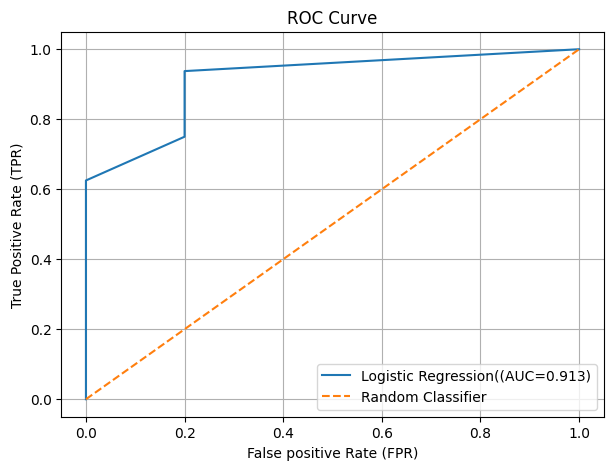

In [86]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr,tpr,thresholds=roc_curve(y_true,y_score)
plt.figure(figsize=(7,5))
plt.plot(fpr,tpr,label=f"Logistic Regression((AUC={auc_score:.3f})")
plt.plot([0,1],[0,1],linestyle="--",label="Random Classifier")
plt.xlabel("False positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC Curve")
plt.legend()
plt.grid()

In [87]:
y_pred_default = pipeline.predict(X_test)

print(y_pred_default[:10])

['Sleep Apnea' 'Insomnia' 'Sleep Apnea' 'Insomnia' 'Sleep Apnea'
 'Insomnia' 'Sleep Apnea' 'Insomnia' 'Insomnia' 'Sleep Apnea']


In [88]:
y_score = pipeline.predict_proba(X_test)[:, 1]

y_pred_03 = np.where(y_score >= 0.3, "Sleep Apnea", "Insomnia")

print(y_pred_03[:10])

['Sleep Apnea' 'Insomnia' 'Sleep Apnea' 'Insomnia' 'Sleep Apnea'
 'Insomnia' 'Sleep Apnea' 'Insomnia' 'Insomnia' 'Sleep Apnea']


In [89]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Default (0.5)": y_pred_default,
    "Threshold (0.3)": y_pred_03
})

comparison.head(10)

,Actual,Default (0.5),Threshold (0.3)
0,Sleep Apnea,Sleep Apnea,Sleep Apnea
1,Insomnia,Insomnia,Insomnia
2,Sleep Apnea,Sleep Apnea,Sleep Apnea
3,Insomnia,Insomnia,Insomnia
4,Sleep Apnea,Sleep Apnea,Sleep Apnea
5,Insomnia,Insomnia,Insomnia
6,Sleep Apnea,Sleep Apnea,Sleep Apnea
7,Insomnia,Insomnia,Insomnia
8,Insomnia,Insomnia,Insomnia
9,Sleep Apnea,Sleep Apnea,Sleep Apnea


In [90]:
print("Total predictions:", len(y_pred_default))

print("Changed predictions:",
      np.sum(y_pred_default != y_pred_03))

print("Same predictions:",
      np.sum(y_pred_default == y_pred_03))

Total predictions: 31
Changed predictions: 2
Same predictions: 29


In [91]:
changed = y_pred_default != y_pred_03

comparison.loc[changed]

,Actual,Default (0.5),Threshold (0.3)
10,Sleep Apnea,Insomnia,Sleep Apnea
24,Sleep Apnea,Insomnia,Sleep Apnea


In [92]:
from sklearn.metrics import accuracy_score

acc_default = accuracy_score(y_test, y_pred_default)
acc_03 = accuracy_score(y_test, y_pred_03)

print("Default Accuracy:", acc_default)
print("Threshold 0.3 Accuracy:", acc_03)

Default Accuracy: 0.7741935483870968
Threshold 0.3 Accuracy: 0.8387096774193549


In [93]:
from sklearn.metrics import confusion_matrix

cm_default = confusion_matrix(y_test, y_pred_default)
cm_03 = confusion_matrix(y_test, y_pred_03)

print("Default Threshold (0.5):")
print(cm_default)

print("\nThreshold (0.3):")
print(cm_03)

Default Threshold (0.5):
[[12  3]
 [ 4 12]]

Threshold (0.3):
[[12  3]
 [ 2 14]]


In [94]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Default threshold (0.5)
metrics_default = {
    "Accuracy": accuracy_score(y_test, y_pred_default),
    "Precision": precision_score(y_test, y_pred_default, pos_label="Sleep Apnea"),
    "Recall": recall_score(y_test, y_pred_default, pos_label="Sleep Apnea"),
    "F1-Score": f1_score(y_test, y_pred_default, pos_label="Sleep Apnea")
}

# Custom threshold (0.3)
metrics_03 = {
    "Accuracy": accuracy_score(y_test, y_pred_03),
    "Precision": precision_score(y_test, y_pred_03, pos_label="Sleep Apnea"),
    "Recall": recall_score(y_test, y_pred_03, pos_label="Sleep Apnea"),
    "F1-Score": f1_score(y_test, y_pred_03, pos_label="Sleep Apnea")
}

print("Default Threshold (0.5):")
print(metrics_default)

print("\nThreshold (0.3):")
print(metrics_03)

Default Threshold (0.5):
{'Accuracy': 0.7741935483870968, 'Precision': 0.8, 'Recall': 0.75, 'F1-Score': 0.7741935483870968}

Threshold (0.3):
{'Accuracy': 0.8387096774193549, 'Precision': 0.8235294117647058, 'Recall': 0.875, 'F1-Score': 0.8484848484848485}


In [95]:
comparison_df = pd.DataFrame({
    "Threshold 0.5": metrics_default,
    "Threshold 0.3": metrics_03
})

comparison_df["Improvement"] = (
    comparison_df["Threshold 0.3"] - comparison_df["Threshold 0.5"]
)

comparison_df

,Threshold 0.5,Threshold 0.3,Improvement
Accuracy,0.774194,0.838710,0.064516
Precision,0.800000,0.823529,0.023529
Recall,0.750000,0.875000,0.125000
F1-Score,0.774194,0.848485,0.074291


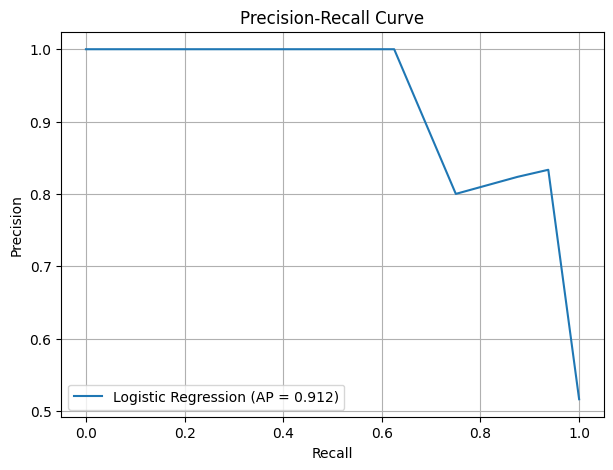

In [96]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

precision, recall, thresholds_pr = precision_recall_curve(y_true, y_score)

ap_score = average_precision_score(y_true, y_score)

plt.figure(figsize=(7, 5))

plt.plot(recall, precision, label=f"Logistic Regression (AP = {ap_score:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid()

plt.show()


In [97]:
error_mask = y_test != y_pred_default

misclassified = X_test.loc[error_mask].copy()

misclassified["Actual"] = y_test.loc[error_mask]
misclassified["Predicted"] = y_pred_default[error_mask]

misclassified


,Gender,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps,Occupation_Doctor,Occupation_Engineer,...,Occupation_Scientist,Occupation_Software Engineer,Occupation_Teacher,BMI Category_Normal Weight,BMI Category_Obese,BMI Category_Overweight,Systolic BP,Diastolic BP,Actual,Predicted
93,0,35,7.4,7,60,5,84,3300,0,0,...,0,0,0,0,1,0,135,88,Sleep Apnea,Insomnia
18,1,29,6.5,5,40,7,80,4000,0,0,...,0,0,0,1,0,0,132,87,Insomnia,Sleep Apnea
104,1,36,7.2,8,60,4,68,7000,0,0,...,0,0,1,0,0,0,115,75,Sleep Apnea,Insomnia
185,1,42,6.8,6,45,7,78,5000,0,0,...,0,0,1,0,0,1,130,85,Sleep Apnea,Insomnia
219,0,43,6.5,6,45,7,72,6000,0,0,...,0,0,0,0,0,1,130,85,Sleep Apnea,Insomnia
264,0,48,7.3,7,65,5,83,3500,1,0,...,0,0,0,0,1,0,142,92,Insomnia,Sleep Apnea
6,0,29,6.3,6,40,7,82,3500,0,0,...,0,0,1,0,1,0,140,90,Insomnia,Sleep Apnea


In [98]:
misclassified["Error Type"] = np.where(
    misclassified["Actual"] == "Sleep Apnea",
    "False Negative",
    "False Positive"
)

misclassified[["Actual", "Predicted", "Error Type"]]

,Actual,Predicted,Error Type
93,Sleep Apnea,Insomnia,False Negative
18,Insomnia,Sleep Apnea,False Positive
104,Sleep Apnea,Insomnia,False Negative
185,Sleep Apnea,Insomnia,False Negative
219,Sleep Apnea,Insomnia,False Negative
264,Insomnia,Sleep Apnea,False Positive
6,Insomnia,Sleep Apnea,False Positive


In [99]:
misclassified["Error Type"].value_counts()

Error Type
False Negative    4
False Positive    3
Name: count, dtype: int64

In [100]:
numeric_cols = [
    "Age",
    "Sleep Duration",
    "Quality of Sleep",
    "Physical Activity Level",
    "Stress Level",
    "Heart Rate",
    "Daily Steps",
    "Systolic BP",
    "Diastolic BP"
]

correct_mask = (y_test.to_numpy() == y_pred_default)

correct_rows = X_test.iloc[correct_mask]

feature_comparison = pd.DataFrame({
    "Correct Predictions": correct_rows[numeric_cols].mean(),
    "Misclassified Predictions": misclassified[numeric_cols].mean()
})

feature_comparison

,Correct Predictions,Misclassified Predictions
Age,47.250000,37.428571
Sleep Duration,6.687500,6.857143
Quality of Sleep,6.666667,6.428571
Physical Activity Level,59.458333,50.714286
Stress Level,5.958333,6.000000
Heart Rate,71.541667,78.142857
Daily Steps,6883.333333,4614.285714
Systolic BP,135.458333,132.000000
Diastolic BP,90.250000,86.000000


In [101]:
error_summary = misclassified["Error Type"].value_counts()

print("Error Summary:")
print(error_summary)

print("\nMisclassified Records:", len(misclassified))
print("Total Test Records:", len(y_test))


Error Summary:
Error Type
False Negative    4
False Positive    3
Name: count, dtype: int64

Misclassified Records: 7
Total Test Records: 31


In [102]:
error_type_comparison = misclassified.groupby("Error Type")[numeric_cols].mean().T

error_type_comparison.round(2)


Error Type,False Negative,False Positive
Age,39.00,35.33
Sleep Duration,6.98,6.70
Quality of Sleep,6.75,6.00
Physical Activity Level,52.50,48.33
Stress Level,5.75,6.33
Heart Rate,75.50,81.67
Daily Steps,5325.00,3666.67
Systolic BP,127.50,138.00
Diastolic BP,83.25,89.67


In [103]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
import numpy as np

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

validation_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

validation_pipeline.fit(X_subtrain, y_subtrain)

val_proba = validation_pipeline.predict_proba(X_val)

positive_index = list(validation_pipeline.classes_).index("Sleep Apnea")
val_score = val_proba[:, positive_index]

thresholds = np.arange(0.10, 0.91, 0.01)

threshold_results = []

for threshold in thresholds:
    val_pred = np.where(
        val_score >= threshold,
        "Sleep Apnea",
        "Insomnia"
    )

    f1 = f1_score(
        y_val,
        val_pred,
        pos_label="Sleep Apnea"
    )

    threshold_results.append({
        "Threshold": threshold,
        "F1 Score": f1
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.sort_values(
    "F1 Score",
    ascending=False
).head(10)

,Threshold,F1 Score
0,0.10,1.000000
1,0.11,0.956522
2,0.12,0.956522
3,0.13,0.956522
4,0.14,0.956522
5,0.15,0.956522
6,0.16,0.956522
7,0.17,0.956522
8,0.18,0.956522
9,0.19,0.956522


In [104]:
best_threshold = threshold_df.loc[
    threshold_df["F1 Score"].idxmax(),
    "Threshold"
]

print("Best Validation Threshold:", best_threshold)

Best Validation Threshold: 0.1


In [105]:
final_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

final_pipeline.fit(X_train, y_train)

print("Final model trained successfully!")

Final model trained successfully!


In [106]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

test_proba = final_pipeline.predict_proba(X_test)

positive_index = list(final_pipeline.classes_).index("Sleep Apnea")
test_score = test_proba[:, positive_index]

y_pred_final = np.where(
    test_score >= best_threshold,
    "Sleep Apnea",
    "Insomnia"
)

print("Selected Threshold:", best_threshold)
print("Test Accuracy:", accuracy_score(y_test, y_pred_final))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred_final,
    labels=["Insomnia", "Sleep Apnea"]
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_final,
    labels=["Insomnia", "Sleep Apnea"]
))

Selected Threshold: 0.1
Test Accuracy: 0.8709677419354839

Confusion Matrix:
[[12  3]
 [ 1 15]]

Classification Report:
              precision    recall  f1-score   support

    Insomnia       0.92      0.80      0.86        15
 Sleep Apnea       0.83      0.94      0.88        16

    accuracy                           0.87        31
   macro avg       0.88      0.87      0.87        31
weighted avg       0.88      0.87      0.87        31



In [107]:
import joblib

model_artifact = {
    "pipeline": final_pipeline,
    "threshold": float(best_threshold),
    "positive_class": "Sleep Apnea",
    "feature_columns": list(X_train.columns)
}

joblib.dump(model_artifact, "sleep_disorder_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [108]:
model_artifact = joblib.load("sleep_disorder_model.pkl")

final_pipeline = model_artifact["pipeline"]
best_threshold = model_artifact["threshold"]
feature_columns = model_artifact["feature_columns"]

print("Model loaded!")
print("Threshold:", best_threshold)

Model loaded!
Threshold: 0.1


In [110]:
def predict_sleep_disorder(input_data, model_artifact):

    pipeline = model_artifact["pipeline"]
    threshold = model_artifact["threshold"]
    feature_columns = model_artifact["feature_columns"]

    input_df = pd.DataFrame([input_data])

    input_df = input_df[feature_columns]

    probabilities = pipeline.predict_proba(input_df)

    positive_index = list(pipeline.classes_).index("Sleep Apnea")

    sleep_apnea_probability = probabilities[0, positive_index]

    prediction = (
        "Sleep Apnea"
        if sleep_apnea_probability >= threshold
        else "Insomnia"
    )

    return {
        "Prediction": prediction,
        "Sleep Apnea Probability": round(float(sleep_apnea_probability), 4),
        "Threshold Used": threshold
    }

In [111]:
sample_input = X_test.iloc[0].to_dict()

result = predict_sleep_disorder(
    sample_input,
    model_artifact
)

print(result)

{'Prediction': 'Sleep Apnea', 'Sleep Apnea Probability': 0.9548, 'Threshold Used': 0.1}


In [112]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
import numpy as np
import pandas as pd

# Training data ko subtrain aur validation mein divide karna
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Pipeline
validation_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

# Model training
validation_pipeline.fit(X_subtrain, y_subtrain)

# Validation probabilities
val_proba = validation_pipeline.predict_proba(X_val)

# Sleep Apnea ka class index find karna
positive_index = list(validation_pipeline.classes_).index("Sleep Apnea")

# Sleep Apnea probabilities
val_score = val_proba[:, positive_index]

# Different thresholds test karna
thresholds = np.arange(0.10, 0.91, 0.01)

threshold_results = []

for threshold in thresholds:

    val_pred = np.where(
        val_score >= threshold,
        "Sleep Apnea",
        "Insomnia"
    )

    f1 = f1_score(
        y_val,
        val_pred,
        pos_label="Sleep Apnea"
    )

    threshold_results.append({
        "Threshold": threshold,
        "F1 Score": f1
    })

# Results ko DataFrame mein convert karna
threshold_df = pd.DataFrame(threshold_results)

# Top 10 thresholds
threshold_df.sort_values(
    "F1 Score",
    ascending=False
).head(10)

,Threshold,F1 Score
0,0.10,1.000000
1,0.11,0.956522
2,0.12,0.956522
3,0.13,0.956522
4,0.14,0.956522
5,0.15,0.956522
6,0.16,0.956522
7,0.17,0.956522
8,0.18,0.956522
9,0.19,0.956522


In [113]:
best_threshold = threshold_df.loc[
    threshold_df["F1 Score"].idxmax(),
    "Threshold"
]

print("Best Validation Threshold:", best_threshold)

Best Validation Threshold: 0.1


In [114]:
final_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

final_pipeline.fit(X_train, y_train)

print("Final model trained successfully!")

Final model trained successfully!


In [115]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

test_proba = final_pipeline.predict_proba(X_test)

positive_index = list(final_pipeline.classes_).index("Sleep Apnea")

test_score = test_proba[:, positive_index]

y_pred_final = np.where(
    test_score >= best_threshold,
    "Sleep Apnea",
    "Insomnia"
)

print("Selected Threshold:", best_threshold)

print("\nTest Accuracy:")
print(accuracy_score(y_test, y_pred_final))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred_final,
    labels=["Insomnia", "Sleep Apnea"]
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_final,
    labels=["Insomnia", "Sleep Apnea"]
))

Selected Threshold: 0.1

Test Accuracy:
0.8709677419354839

Confusion Matrix:
[[12  3]
 [ 1 15]]

Classification Report:
              precision    recall  f1-score   support

    Insomnia       0.92      0.80      0.86        15
 Sleep Apnea       0.83      0.94      0.88        16

    accuracy                           0.87        31
   macro avg       0.88      0.87      0.87        31
weighted avg       0.88      0.87      0.87        31



In [116]:
import joblib

model_artifact = {
    "pipeline": final_pipeline,
    "threshold": float(best_threshold),
    "positive_class": "Sleep Apnea",
    "feature_columns": list(X_train.columns)
}

joblib.dump(model_artifact, "sleep_disorder_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [117]:
model_artifact = joblib.load("sleep_disorder_model.pkl")

final_pipeline = model_artifact["pipeline"]
best_threshold = model_artifact["threshold"]
feature_columns = model_artifact["feature_columns"]

print("Model loaded successfully!")
print("Threshold:", best_threshold)
print("Features:", len(feature_columns))

Model loaded successfully!
Threshold: 0.1
Features: 23


In [118]:
def predict_sleep_disorder(input_data, model_artifact):

    pipeline = model_artifact["pipeline"]
    threshold = model_artifact["threshold"]
    feature_columns = model_artifact["feature_columns"]

    input_df = pd.DataFrame([input_data])
    input_df = input_df[feature_columns]

    probabilities = pipeline.predict_proba(input_df)

    positive_index = list(pipeline.classes_).index("Sleep Apnea")

    sleep_apnea_probability = probabilities[0, positive_index]

    prediction = (
        "Sleep Apnea"
        if sleep_apnea_probability >= threshold
        else "Insomnia"
    )

    return {
        "Prediction": prediction,
        "Sleep Apnea Probability": round(float(sleep_apnea_probability), 4),
        "Threshold Used": threshold
    }

In [119]:
sample_input = X_test.iloc[0].to_dict()

result = predict_sleep_disorder(sample_input, model_artifact)

print(result)

{'Prediction': 'Sleep Apnea', 'Sleep Apnea Probability': 0.9548, 'Threshold Used': 0.1}
